# 05 · Market-wide comparison and robustness checks

## Purpose

This notebook tests whether the main price-demand conclusions remain stable under reasonable alternative specifications.

It first estimates the advertised price-demand relationship across the NYC market without segmentation. It then tests whether that relationship differs across the five listing segments through a price-by-segment interaction model.

The remaining checks examine whether the main conclusions are sensitive to the treatment of extreme demand values, a stricter availability threshold and the main modelling choices made earlier.

## 1. Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

from scipy.stats import spearmanr

## 2. Configuration

In [2]:
MAIN_DEMAND_CAP = 0.99
ALTERNATIVE_DEMAND_CAP = 0.95
MAIN_AVAILABILITY_THRESHOLD = 30
STRICT_AVAILABILITY_THRESHOLD = 60

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "airbnb_cleaned_features.csv"

BASELINE_DIR = PROJECT_ROOT / "outputs" / "clustering" / "baseline"
BASELINE_LABELS_PATH = BASELINE_DIR / "baseline_cluster_labels.csv"
BASELINE_EVALUATION_PATH = BASELINE_DIR / "baseline_cluster_evaluation.csv"

PRICING_DIR = PROJECT_ROOT / "outputs" / "pricing"
PRICING_COMPARISON_PATH = PRICING_DIR / "model_comparison.csv"

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "robustness"
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 3. Load and merge the analysis data

The processed listing data is merged with the final five-cluster baseline labels. The same segment names used in the segment-level analysis are reconstructed from room type and centrality.

In [3]:
required_files = [
    DATA_PATH,
    BASELINE_LABELS_PATH,
    BASELINE_EVALUATION_PATH,
    PRICING_COMPARISON_PATH,
]

missing_files = [path for path in required_files if not path.exists()]

if missing_files:
    raise FileNotFoundError(
        "Required files were not found:\n"
        + "\n".join(str(path) for path in missing_files)
    )

df = pd.read_csv(DATA_PATH)
baseline_labels = pd.read_csv(BASELINE_LABELS_PATH)
baseline_evaluation = pd.read_csv(BASELINE_EVALUATION_PATH)
pricing_comparison = pd.read_csv(PRICING_COMPARISON_PATH)

analysis_df = df.merge(
    baseline_labels[["id", "cluster"]],
    on="id",
    how="inner",
    validate="one_to_one",
)

if analysis_df["cluster"].nunique() != 5:
    raise ValueError("The final baseline segmentation should contain five clusters.")

print(f"Processed listings: {len(df):,}")
print(f"Listings with final segment labels: {len(analysis_df):,}")

Processed listings: 31,340
Listings with final segment labels: 31,340


In [4]:
def dominant_value(series):
    mode = series.dropna().mode()
    return mode.iloc[0] if len(mode) else "Unknown"


def location_description(distance_km):
    if distance_km < 6:
        return "Central"
    if distance_km <= 12:
        return "Less-central"
    return "Outer"


def room_description(room_type):
    mapping = {
        "Entire home/apt": "entire homes",
        "Private room": "private rooms",
        "Shared room": "shared rooms",
    }
    return mapping.get(room_type, str(room_type).lower())


segment_identity = (
    analysis_df
    .groupby("cluster")
    .agg(
        dominant_room_type=("room_type", dominant_value),
        median_distance_km=("dist_center_km", "median"),
    )
    .reset_index()
)

segment_identity["segment"] = segment_identity.apply(
    lambda row: (
        f"{location_description(row['median_distance_km'])} "
        f"{room_description(row['dominant_room_type'])}"
    ),
    axis=1,
)

segment_name_map = dict(
    zip(segment_identity["cluster"], segment_identity["segment"])
)

analysis_df["segment"] = analysis_df["cluster"].map(segment_name_map)

display(segment_identity.round(2))

,cluster,dominant_room_type,median_distance_km,segment
0,0,Private room,17.590,Outer private rooms
1,1,Entire home/apt,3.380,Central entire homes
2,2,Private room,4.820,Central private rooms
3,3,Private room,9.460,Less-central private rooms
4,4,Entire home/apt,9.260,Less-central entire homes


## 4. Main reliable demand sample

The main specification uses listings with at least 30 available days and caps the demand proxy at the 99th percentile. This reproduces the assumptions used in the segment-level analysis.

In [5]:
main_demand_df = analysis_df.loc[
    analysis_df["availability_365"].ge(MAIN_AVAILABILITY_THRESHOLD)
    & analysis_df["demand_rate_year"].notna()
    & np.isfinite(analysis_df["demand_rate_year"])
    & analysis_df["price"].gt(0)
].copy()

main_cap_value = main_demand_df["demand_rate_year"].quantile(
    MAIN_DEMAND_CAP
)

main_demand_df["demand_analysis"] = (
    main_demand_df["demand_rate_year"]
    .clip(upper=main_cap_value)
)

print(f"Main demand observations: {len(main_demand_df):,}")
print(f"99th percentile cap: {main_cap_value:,.2f}")

Main demand observations: 26,175
99th percentile cap: 486.71


## 5. Market-wide price-demand relationship

The first model estimates the adjusted relationship between advertised price and the demand proxy across the whole market, without using the cluster labels.

This provides a market-wide benchmark against which the segment-specific relationships can be compared.

In [6]:
market_model_data = main_demand_df[
    [
        "demand_analysis",
        "price",
        "minimum_nights",
        "calculated_host_listings_count",
        "dist_center_km",
        "room_type",
        "neighbourhood_group",
    ]
].dropna().copy()

market_model_data["log_demand"] = np.log1p(
    market_model_data["demand_analysis"]
)
market_model_data["log_price"] = np.log(
    market_model_data["price"]
)
market_model_data["log_minimum_nights"] = np.log1p(
    market_model_data["minimum_nights"]
)
market_model_data["log_host_listings"] = np.log1p(
    market_model_data["calculated_host_listings_count"]
)

market_model = smf.ols(
    (
        "log_demand ~ log_price "
        "+ log_minimum_nights "
        "+ log_host_listings "
        "+ dist_center_km "
        "+ C(room_type) "
        "+ C(neighbourhood_group)"
    ),
    data=market_model_data,
).fit(cov_type="HC3")

market_ci = market_model.conf_int().loc["log_price"]

market_model_summary = pd.DataFrame(
    {
        "n": [int(market_model.nobs)],
        "adjusted_log_price_coefficient": [
            market_model.params["log_price"]
        ],
        "coefficient_ci_lower": [market_ci.iloc[0]],
        "coefficient_ci_upper": [market_ci.iloc[1]],
        "model_r2": [market_model.rsquared],
    }
)

display(market_model_summary.round(3))

,n,adjusted_log_price_coefficient,coefficient_ci_lower,coefficient_ci_upper,model_r2
0,26175,-0.702,-0.741,-0.664,0.263


## 6. Test whether the price-demand relationship differs by segment

A single interaction model allows the slope on advertised price to vary across the five segments while retaining the same controls.

Central entire homes are used as the reference segment. The segment-specific slopes are reconstructed from the fitted interaction terms and can be compared directly with the market-wide coefficient.

In [7]:
interaction_data = main_demand_df[
    [
        "segment",
        "demand_analysis",
        "price",
        "minimum_nights",
        "calculated_host_listings_count",
        "dist_center_km",
        "room_type",
        "neighbourhood_group",
    ]
].dropna().copy()

interaction_data["log_demand"] = np.log1p(
    interaction_data["demand_analysis"]
)
interaction_data["log_price"] = np.log(
    interaction_data["price"]
)
interaction_data["log_minimum_nights"] = np.log1p(
    interaction_data["minimum_nights"]
)
interaction_data["log_host_listings"] = np.log1p(
    interaction_data["calculated_host_listings_count"]
)

reference_segment = "Central entire homes"

interaction_formula = (
    "log_demand ~ "
    "log_price * C(segment, Treatment(reference=reference_segment)) "
    "+ log_minimum_nights "
    "+ log_host_listings "
    "+ dist_center_km "
    "+ C(room_type) "
    "+ C(neighbourhood_group)"
)

interaction_model = smf.ols(
    interaction_formula,
    data=interaction_data,
).fit(cov_type="HC3")

base_slope = interaction_model.params["log_price"]
base_var = interaction_model.cov_params().loc["log_price", "log_price"]

slope_rows = []

for segment in sorted(interaction_data["segment"].unique()):
    if segment == reference_segment:
        slope = base_slope
        variance = base_var
    else:
        term = (
            "log_price:C(segment, "
            f"Treatment(reference=reference_segment))[T.{segment}]"
        )

        slope = base_slope + interaction_model.params[term]

        covariance = interaction_model.cov_params()
        variance = (
            covariance.loc["log_price", "log_price"]
            + covariance.loc[term, term]
            + 2 * covariance.loc["log_price", term]
        )

    standard_error = np.sqrt(variance)

    slope_rows.append(
        {
            "segment": segment,
            "adjusted_log_price_coefficient": slope,
            "ci_lower": slope - 1.96 * standard_error,
            "ci_upper": slope + 1.96 * standard_error,
        }
    )

interaction_slopes = (
    pd.DataFrame(slope_rows)
    .sort_values("adjusted_log_price_coefficient")
    .reset_index(drop=True)
)

display(interaction_slopes.round(3))

,segment,adjusted_log_price_coefficient,ci_lower,ci_upper
0,Outer private rooms,-0.898,-1.008,-0.787
1,Less-central private rooms,-0.842,-0.947,-0.737
2,Central private rooms,-0.745,-0.831,-0.659
3,Less-central entire homes,-0.737,-0.814,-0.660
4,Central entire homes,-0.540,-0.600,-0.479


## 7. Joint test of the price-by-segment interactions

The interaction terms are tested jointly against zero. A small p-value indicates that a single market-wide price coefficient does not adequately describe all five segments.

In [8]:
interaction_terms = [
    name
    for name in interaction_model.params.index
    if name.startswith("log_price:C(segment")
]

if interaction_terms:
    restriction = ", ".join(
        f"{term} = 0"
        for term in interaction_terms
    )

    interaction_test = interaction_model.f_test(restriction)

    interaction_test_summary = pd.DataFrame(
        {
            "f_statistic": [float(np.asarray(interaction_test.fvalue).squeeze())],
            "p_value": [float(np.asarray(interaction_test.pvalue).squeeze())],
            "interaction_terms_tested": [len(interaction_terms)],
        }
    )
else:
    interaction_test_summary = pd.DataFrame(
        {
            "f_statistic": [np.nan],
            "p_value": [np.nan],
            "interaction_terms_tested": [0],
        }
    )

display(interaction_test_summary.round(4))

,f_statistic,p_value,interaction_terms_tested
0,12.521,0.000,4


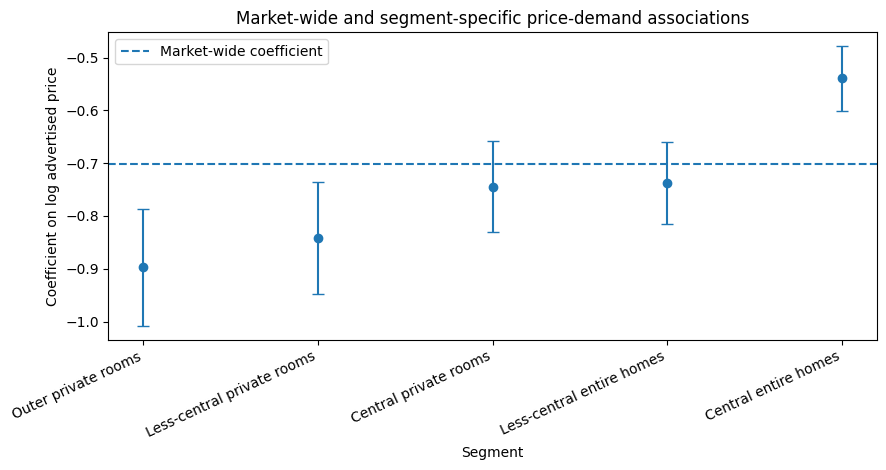

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.8))

plot_slopes = interaction_slopes.copy()
x = np.arange(len(plot_slopes))

coefs = plot_slopes["adjusted_log_price_coefficient"].to_numpy()
lower = plot_slopes["ci_lower"].to_numpy()
upper = plot_slopes["ci_upper"].to_numpy()

ax.errorbar(
    x,
    coefs,
    yerr=np.vstack([coefs - lower, upper - coefs]),
    fmt="o",
    capsize=4,
)

ax.axhline(
    market_model.params["log_price"],
    linestyle="--",
    label="Market-wide coefficient",
)

ax.set_xticks(x)
ax.set_xticklabels(
    plot_slopes["segment"],
    rotation=25,
    ha="right",
)
ax.set_title("Market-wide and segment-specific price-demand associations")
ax.set_ylabel("Coefficient on log advertised price")
ax.set_xlabel("Segment")
ax.legend()

plt.tight_layout()
fig.savefig(
    FIGURE_DIR / "market_vs_segment_price_associations.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 8. Demand-cap sensitivity

The segment findings are recalculated using three treatments of the demand proxy:

- no upper cap;
- the main 99th percentile cap;
- a stricter 95th percentile cap.

The purpose is to check whether the headline conclusions depend on a small number of extreme demand values.

In [10]:
def prepare_demand_specification(data, quantile=None):
    prepared = data.loc[
        data["availability_365"].ge(MAIN_AVAILABILITY_THRESHOLD)
        & data["demand_rate_year"].notna()
        & np.isfinite(data["demand_rate_year"])
        & data["price"].gt(0)
    ].copy()

    if quantile is None:
        prepared["demand_analysis"] = prepared["demand_rate_year"]
    else:
        cap = prepared["demand_rate_year"].quantile(quantile)
        prepared["demand_analysis"] = (
            prepared["demand_rate_year"].clip(upper=cap)
        )

    return prepared


def fit_segment_models(data):
    rows = []

    for segment, group in data.groupby("segment"):
        model_data = group[
            [
                "demand_analysis",
                "price",
                "minimum_nights",
                "calculated_host_listings_count",
                "dist_center_km",
                "room_type",
                "neighbourhood_group",
            ]
        ].dropna().copy()

        model_data["log_demand"] = np.log1p(
            model_data["demand_analysis"]
        )
        model_data["log_price"] = np.log(
            model_data["price"]
        )
        model_data["log_minimum_nights"] = np.log1p(
            model_data["minimum_nights"]
        )
        model_data["log_host_listings"] = np.log1p(
            model_data["calculated_host_listings_count"]
        )

        model = smf.ols(
            (
                "log_demand ~ log_price "
                "+ log_minimum_nights "
                "+ log_host_listings "
                "+ dist_center_km "
                "+ C(room_type) "
                "+ C(neighbourhood_group)"
            ),
            data=model_data,
        ).fit(cov_type="HC3")

        rows.append(
            {
                "segment": segment,
                "n": int(model.nobs),
                "median_demand": group["demand_analysis"].median(),
                "adjusted_log_price_coefficient": model.params["log_price"],
            }
        )

    result = pd.DataFrame(rows)

    return result


cap_specifications = {
    "Uncapped": None,
    "P99 cap": MAIN_DEMAND_CAP,
    "P95 cap": ALTERNATIVE_DEMAND_CAP,
}

cap_results = []

for specification, quantile in cap_specifications.items():
    specification_data = prepare_demand_specification(
        analysis_df,
        quantile=quantile,
    )

    segment_results = fit_segment_models(
        specification_data
    )

    segment_results["specification"] = specification
    cap_results.append(segment_results)

cap_sensitivity = pd.concat(
    cap_results,
    ignore_index=True,
)

display(
    cap_sensitivity[
        [
            "specification",
            "segment",
            "n",
            "median_demand",
            "adjusted_log_price_coefficient",
        ]
    ]
    .sort_values(["specification", "segment"])
    .round(3)
)

,specification,segment,n,median_demand,adjusted_log_price_coefficient
10,P95 cap,Central entire homes,7954,13.050,-0.470
11,P95 cap,Central private rooms,4851,22.260,-0.819
12,P95 cap,Less-central entire homes,4994,33.205,-0.726
13,P95 cap,Less-central private rooms,5987,22.450,-0.797
14,P95 cap,Outer private rooms,2389,24.470,-1.014
5,P99 cap,Central entire homes,7954,13.050,-0.481
6,P99 cap,Central private rooms,4851,22.260,-0.838
7,P99 cap,Less-central entire homes,4994,33.205,-0.742
8,P99 cap,Less-central private rooms,5987,22.450,-0.813
9,P99 cap,Outer private rooms,2389,24.470,-1.039


## 9. Availability-threshold sensitivity

The main analysis excludes listings with fewer than 30 available days. A stricter threshold of 60 days is used as a sensitivity check.

The analysis then tests whether the same segments remain highest in demand, most price-resilient and most price-sensitive.

In [11]:
def analyse_threshold(data, threshold, cap_quantile=0.99):
    subset = data.loc[
        data["availability_365"].ge(threshold)
        & data["demand_rate_year"].notna()
        & np.isfinite(data["demand_rate_year"])
        & data["price"].gt(0)
    ].copy()

    cap = subset["demand_rate_year"].quantile(cap_quantile)
    subset["demand_analysis"] = subset["demand_rate_year"].clip(
        upper=cap
    )

    results = fit_segment_models(subset)

    highest_demand = results.loc[
        results["median_demand"].idxmax()
    ]
    most_resilient = results.loc[
        results["adjusted_log_price_coefficient"].idxmax()
    ]
    most_sensitive = results.loc[
        results["adjusted_log_price_coefficient"].idxmin()
    ]

    summary = {
        "availability_threshold": threshold,
        "n": len(subset),
        "highest_demand_segment": highest_demand["segment"],
        "most_price_resilient_segment": most_resilient["segment"],
        "most_price_sensitive_segment": most_sensitive["segment"],
    }

    return results, summary


threshold_results = []
threshold_summaries = []

for threshold in [
    MAIN_AVAILABILITY_THRESHOLD,
    STRICT_AVAILABILITY_THRESHOLD,
]:
    result, summary = analyse_threshold(
        analysis_df,
        threshold=threshold,
        cap_quantile=MAIN_DEMAND_CAP,
    )

    result["availability_threshold"] = threshold

    threshold_results.append(result)
    threshold_summaries.append(summary)

threshold_sensitivity = pd.concat(
    threshold_results,
    ignore_index=True,
)

threshold_summary = pd.DataFrame(
    threshold_summaries
)

display(threshold_summary)

,availability_threshold,n,highest_demand_segment,most_price_resilient_segment,most_price_sensitive_segment
0,30,26175,Less-central entire homes,Central entire homes,Outer private rooms
1,60,23163,Less-central entire homes,Central entire homes,Outer private rooms


## 10. Pricing-model robustness

The pricing model comparison is reused to check whether the main conclusion depends heavily on selecting one particular nonlinear algorithm.

The focus is on whether CatBoost and Random Forest both outperform the linear alternatives and whether their cross-validation performance is materially different.

In [12]:
display(
    pricing_comparison[
        [
            "model",
            "cv_rmse_log10",
            "mae_usd",
            "rmse_usd",
            "r2_log10",
            "r2_usd",
        ]
    ]
    .sort_values("cv_rmse_log10")
    .round(4)
)

tree_models = pricing_comparison.loc[
    pricing_comparison["model"].isin(
        ["CatBoost", "Random Forest"]
    )
].copy()

if len(tree_models) == 2:
    tree_cv_gap = (
        tree_models["cv_rmse_log10"].max()
        - tree_models["cv_rmse_log10"].min()
    )

    print(
        f"Cross-validation RMSE gap between "
        f"CatBoost and Random Forest: {tree_cv_gap:.4f}"
    )

,model,cv_rmse_log10,mae_usd,rmse_usd,r2_log10,r2_usd
0,CatBoost,0.190,61.887,224.887,0.620,0.156
1,Random Forest,0.191,61.138,224.501,0.620,0.159
2,OLS,0.208,66.820,230.779,0.545,0.111
3,Elastic Net,0.209,66.915,231.115,0.541,0.108
4,Median benchmark,0.313,92.342,250.037,-0.006,-0.043


Cross-validation RMSE gap between CatBoost and Random Forest: 0.0010


## 11. Clustering-model robustness

The baseline candidate table is revisited to show the trade-off between separation, stability and complexity.

The five-cluster solution remains useful if it provides the strongest separation while neighbouring alternatives mainly offer either fewer segments or greater stability without the same level of separation.

In [13]:
display(
    baseline_evaluation[
        [
            "k",
            "silhouette",
            "stability_ari",
            "smallest_cluster_n",
            "largest_cluster_n",
            "smallest_cluster_share",
        ]
    ]
    .sort_values("k")
    .round(4)
)

selected_baseline = baseline_evaluation.loc[
    baseline_evaluation["silhouette"].idxmax()
]

most_stable = baseline_evaluation.loc[
    baseline_evaluation["stability_ari"].idxmax()
]

print(
    f"Highest silhouette: k={int(selected_baseline['k'])}, "
    f"{selected_baseline['silhouette']:.3f}"
)
print(
    f"Highest stability: k={int(most_stable['k'])}, "
    f"{most_stable['stability_ari']:.3f}"
)

,k,silhouette,stability_ari,smallest_cluster_n,largest_cluster_n,smallest_cluster_share
0,2,0.564,0.998,12304,19036,0.393
1,3,0.557,0.999,5910,14650,0.189
2,4,0.611,0.999,4085,10844,0.130
3,5,0.659,0.763,2544,9732,0.081
4,6,0.655,0.782,1935,7626,0.062
5,7,0.643,0.751,1398,6470,0.045
6,8,0.657,0.944,1019,6104,0.033


Highest silhouette: k=5, 0.660
Highest stability: k=3, 0.999


## 12. Robustness summary

The final table records whether the main conclusions survive the alternative specifications.

A conclusion is treated as robust when its substantive interpretation remains unchanged rather than requiring identical numerical estimates.

In [14]:
main_cap = cap_sensitivity.loc[
    cap_sensitivity["specification"].eq("P99 cap")
]

uncapped = cap_sensitivity.loc[
    cap_sensitivity["specification"].eq("Uncapped")
]

p95 = cap_sensitivity.loc[
    cap_sensitivity["specification"].eq("P95 cap")
]


def headline_segments(frame):
    return {
        "highest_demand": frame.loc[
            frame["median_demand"].idxmax(),
            "segment",
        ],
        "most_resilient": frame.loc[
            frame["adjusted_log_price_coefficient"].idxmax(),
            "segment",
        ],
        "most_sensitive": frame.loc[
            frame["adjusted_log_price_coefficient"].idxmin(),
            "segment",
        ],
    }


main_headlines = headline_segments(main_cap)
uncapped_headlines = headline_segments(uncapped)
p95_headlines = headline_segments(p95)

strict_row = threshold_summary.loc[
    threshold_summary["availability_threshold"].eq(
        STRICT_AVAILABILITY_THRESHOLD
    )
].iloc[0]

interaction_p_value = interaction_test_summary["p_value"].iloc[0]

robustness_summary = pd.DataFrame(
    [
        {
            "finding": "Segment-specific price relationships matter",
            "main_result": "Five segment-specific slopes",
            "alternative_check": (
                f"Interaction test p={interaction_p_value:.4g}"
            ),
            "robust": bool(
                pd.notna(interaction_p_value)
                and interaction_p_value < 0.05
            ),
        },
        {
            "finding": "Highest demand segment",
            "main_result": main_headlines["highest_demand"],
            "alternative_check": (
                f"Uncapped: {uncapped_headlines['highest_demand']}; "
                f"P95: {p95_headlines['highest_demand']}; "
                f"60-day: {strict_row['highest_demand_segment']}"
            ),
            "robust": bool(
                main_headlines["highest_demand"]
                == uncapped_headlines["highest_demand"]
                == p95_headlines["highest_demand"]
                == strict_row["highest_demand_segment"]
            ),
        },
        {
            "finding": "Most price-resilient segment",
            "main_result": main_headlines["most_resilient"],
            "alternative_check": (
                f"Uncapped: {uncapped_headlines['most_resilient']}; "
                f"P95: {p95_headlines['most_resilient']}; "
                f"60-day: {strict_row['most_price_resilient_segment']}"
            ),
            "robust": bool(
                main_headlines["most_resilient"]
                == uncapped_headlines["most_resilient"]
                == p95_headlines["most_resilient"]
                == strict_row["most_price_resilient_segment"]
            ),
        },
        {
            "finding": "Most price-sensitive segment",
            "main_result": main_headlines["most_sensitive"],
            "alternative_check": (
                f"Uncapped: {uncapped_headlines['most_sensitive']}; "
                f"P95: {p95_headlines['most_sensitive']}; "
                f"60-day: {strict_row['most_price_sensitive_segment']}"
            ),
            "robust": bool(
                main_headlines["most_sensitive"]
                == uncapped_headlines["most_sensitive"]
                == p95_headlines["most_sensitive"]
                == strict_row["most_price_sensitive_segment"]
            ),
        },
        {
            "finding": "Nonlinear pricing models strongest",
            "main_result": "CatBoost selected by CV",
            "alternative_check": (
                f"CatBoost-Random Forest CV RMSE gap "
                f"{tree_cv_gap:.4f}"
                if len(tree_models) == 2
                else "Tree-model comparison unavailable"
            ),
            "robust": bool(
                len(tree_models) == 2
                and tree_models["cv_rmse_log10"].max()
                < pricing_comparison.loc[
                    pricing_comparison["model"].isin(
                        ["OLS", "Elastic Net"]
                    ),
                    "cv_rmse_log10",
                ].min()
            ),
        },
        {
            "finding": "Five-cluster baseline has strongest separation",
            "main_result": f"k={int(selected_baseline['k'])}",
            "alternative_check": (
                f"Best silhouette "
                f"{selected_baseline['silhouette']:.3f}; "
                f"stability {selected_baseline['stability_ari']:.3f}"
            ),
            "robust": bool(
                int(selected_baseline["k"]) == 5
            ),
        },
    ]
)

display(robustness_summary)

,finding,main_result,alternative_check,robust
0,Segment-specific price relationships matter,Five segment-specific slopes,Interaction test p=3.547e-10,True
1,Highest demand segment,Less-central entire homes,Uncapped: Less-central entire homes; P95: Less...,True
2,Most price-resilient segment,Central entire homes,Uncapped: Central entire homes; P95: Central e...,True
3,Most price-sensitive segment,Outer private rooms,Uncapped: Outer private rooms; P95: Outer priv...,True
4,Nonlinear pricing models strongest,CatBoost selected by CV,CatBoost-Random Forest CV RMSE gap 0.0010,True
5,Five-cluster baseline has strongest separation,k=5,Best silhouette 0.660; stability 0.763,True


## 13. Interpretation

The market-wide model provides the average adjusted price-demand association across NYC. The interaction model then shows whether that single coefficient hides meaningful differences between listing segments.

The sensitivity checks assess whether the main segment conclusions depend on one particular treatment of extreme demand values or the 30-day availability threshold. The pricing and clustering summaries provide additional evidence that the principal modelling conclusions are not driven by one isolated algorithm or candidate solution.

In [15]:
print("ROBUSTNESS SUMMARY")
print("------------------")
print(
    f"Market-wide adjusted price coefficient: "
    f"{market_model.params['log_price']:.3f}"
)

if pd.notna(interaction_p_value):
    print(
        f"Joint price-by-segment interaction p-value: "
        f"{interaction_p_value:.4g}"
    )

for _, row in robustness_summary.iterrows():
    status = "Yes" if row["robust"] else "No"
    print(f"{row['finding']}: {status}")

ROBUSTNESS SUMMARY
------------------
Market-wide adjusted price coefficient: -0.702
Joint price-by-segment interaction p-value: 3.547e-10
Segment-specific price relationships matter: Yes
Highest demand segment: Yes
Most price-resilient segment: Yes
Most price-sensitive segment: Yes
Nonlinear pricing models strongest: Yes
Five-cluster baseline has strongest separation: Yes


## 14. Save results

In [16]:
market_model_path = OUTPUT_DIR / "market_wide_price_model.csv"
interaction_slopes_path = OUTPUT_DIR / "segment_interaction_slopes.csv"
interaction_test_path = OUTPUT_DIR / "segment_interaction_test.csv"
cap_sensitivity_path = OUTPUT_DIR / "demand_cap_sensitivity.csv"
threshold_sensitivity_path = OUTPUT_DIR / "availability_threshold_sensitivity.csv"
threshold_summary_path = OUTPUT_DIR / "availability_threshold_headlines.csv"
robustness_summary_path = OUTPUT_DIR / "robustness_summary.csv"

market_model_summary.to_csv(market_model_path, index=False)
interaction_slopes.to_csv(interaction_slopes_path, index=False)
interaction_test_summary.to_csv(interaction_test_path, index=False)
cap_sensitivity.to_csv(cap_sensitivity_path, index=False)
threshold_sensitivity.to_csv(threshold_sensitivity_path, index=False)
threshold_summary.to_csv(threshold_summary_path, index=False)
robustness_summary.to_csv(robustness_summary_path, index=False)

print(f"Saved market-wide model: {market_model_path}")
print(f"Saved interaction slopes: {interaction_slopes_path}")
print(f"Saved interaction test: {interaction_test_path}")
print(f"Saved demand-cap sensitivity: {cap_sensitivity_path}")
print(f"Saved threshold sensitivity: {threshold_sensitivity_path}")
print(f"Saved robustness summary: {robustness_summary_path}")
print(f"Saved figures: {FIGURE_DIR}")

Saved market-wide model: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\robustness\market_wide_price_model.csv
Saved interaction slopes: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\robustness\segment_interaction_slopes.csv
Saved interaction test: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\robustness\segment_interaction_test.csv
Saved demand-cap sensitivity: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\robustness\demand_cap_sensitivity.csv
Saved threshold sensitivity: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\robustness\availability_threshold_sensitivity.csv
Saved robustness summary: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\robustness\robustness_summary.csv
Saved figures: C:\Users\iesha\Dropbox\UoE\Module 4 - Machine Learning\Unit 6\assignment\outputs\robustness\figu